In [ ]:
# Google Colab only: download the course data. On your own computer this cell does nothing.
import os, sys, urllib.request

REPO = "https://raw.githubusercontent.com/ChantalNaumann/tutorials/main/"
if "google.colab" in sys.modules:
    for f in ["neurodata.py", "images/anatomy.png"]:
        if not os.path.exists(f):
            os.makedirs(os.path.dirname(f) or ".", exist_ok=True)
            urllib.request.urlretrieve(REPO + f, f)

## 1. Just enough NumPy

About Numpy:
NumPy is a Python library that helps us work with numbers. It lets us store many numbers in arrays and perform calculations on them easily. It is especially useful in science, data analysis, engineering, and machine learning.
A regular Python list can also store numbers. NumPy becomes especially useful when we want to perform the same calculation on many numbers at once.

In [ ]:
import numpy as np

spike_times = np.array([0.12, 0.35, 0.36, 0.80])
print(spike_times * 1000)
print(spike_times[0], spike_times[-1])
print(spike_times[spike_times < 0.5])

[120. 350. 360. 800.]
0.12 0.8
[0.12 0.35 0.36]


Exercise:
1) Add 2 to all the values
2) Print only the 3rd number of the spike times

In [ ]:
#Solution: 
print(spike_times + 2)

print (spike_times[2])

[2.12 2.35 2.36 2.8 ]
0.36


NumPy can calculate simple statistics for us. This makes it really useful for us

In [ ]:
measurements = np.array([10, 20, 30, 40, 50])
print(np.mean(measurements))
print(np.max(measurements))
print(np.sum(measurements))

30.0
50
150


Exercise 
1) Create a numpy array with the name "temperatures" and add the following values to it: 30, 35, 36.5, 25, 27, 40
2) Calculate the mean value of the measured temperatures, find the highest and lowest value and then calculate the sum.Then find the median and calulate the standard devision (np.std(data)

In [ ]:
# Solutions:
temperature = np.array([30, 35, 36.5, 25, 27, 40])

print(np.mean(temperature))
print(np.max(temperature))
print(np.min(temperature))
print(np.sum(temperature))
print(np.median(temperature))
print(np.std(temperature))


32.25
40.0
25.0
193.5
32.5
5.336587548861788


Our data comes from `neurodata.py`: fake but realistic recordings, so we can focus on plotting.

In [ ]:
import neurodata

t, v, current, spikes = neurodata.membrane_potential()

## 2. Figure and Axes

Every plot starts with `fig, ax = plt.subplots()`: `fig` is the whole image, `ax` is the panel you draw in.

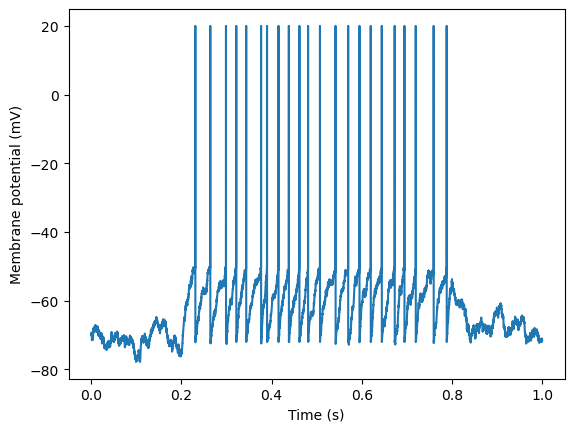

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.plot(t, v)
ax.set(xlabel="Time (s)", ylabel="Membrane potential (mV)")
plt.show()

Excercise:
1)  change the colour to black, the linewidth to 1. hint: commands for this are color and linewidth and you use them when you specify your plotting conditions
2) zoom in on a single spike with `xlim`

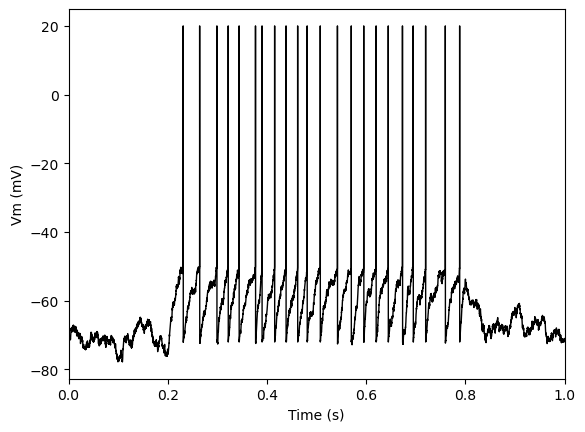

In [ ]:
#Solution
fig, ax = plt.subplots()
ax.plot(t, v, color="black", linewidth=1)
ax.set(xlabel="Time (s)", ylabel="Vm (mV)", xlim=(0, 1))
plt.show()

## 3. The names of things

To change a part of a figure, you need its name:

![anatomy of a figure](images/anatomy.png)

Exercise:
Each part can be set accordingly. Play around with the different settings like suggested and see what happens

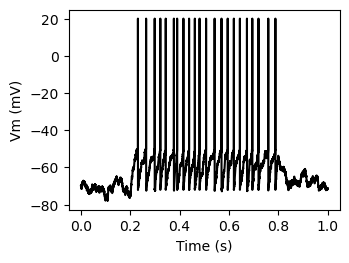

In [ ]:
box = True          # True or False: top and right spines
ticks = "out"       # "out" or "in"
font_size = 10      # try 4 to 16
line_width = 1.5    # try 0.25 to 3

fig, ax = plt.subplots(figsize=(3.5, 2.6))
ax.plot(t, v, color="black", linewidth=line_width)
ax.set_xlabel("Time (s)", fontsize=font_size)
ax.set_ylabel("Vm (mV)", fontsize=font_size)
ax.spines[["top", "right"]].set_visible(box)
ax.tick_params(direction=ticks, labelsize=font_size)
plt.show()

Exercise
Plot  histogram of the inter-spike intervals in ms: `ax.hist(np.diff(spikes) * 1000, bins=10)`and label the axes properly

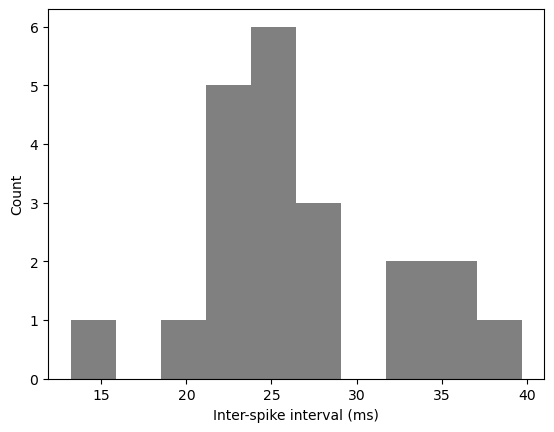

In [ ]:
#Solutiion

fig, ax = plt.subplots()
ax.hist(np.diff(spikes) * 1000, bins=10, color="gray")
ax.set(xlabel="Inter-spike interval (ms)", ylabel="Count")
plt.show()
